# 05 · Los retadores: Random Forest, XGBoost, LightGBM y redes neuronales

**Modelos 2 a 5 (+1).** Cada retador recibió el mismo esfuerzo de ajuste (decisión 005):

- Optimización bayesiana con Optuna (TPE), **25 ensayos por modelo**.
- Objetivo: AUC promedio de **2 cortes temporales** (jul–sep y oct–dic 2014), para no sobreajustar a un solo periodo.
- **2015 no se tocó durante el ajuste:** es el examen final.
- Hardware: XGBoost y la red PyTorch en **GPU (RTX 5070)**; el resto en CPU.

El ajuste corre con `python -m credit_lab.ajustar`; este notebook lee sus resultados (`modelos/`).

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from credit_lab.metricas import discriminacion, resumen

pd.set_option("display.float_format", "{:,.4f}".format)
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

# Color fijo por modelo (el mismo en todos los gráficos)
NOMBRES = {"logistica": "Logística", "int_rate": "int_rate (Lending Club)", "lgbm": "LightGBM",
           "xgb": "XGBoost", "torch": "Red PyTorch", "mlp": "Red scikit-learn", "rf": "Random Forest"}
COLOR = {"logistica": "#2a78d6", "int_rate": "#eb6834", "lgbm": "#1baf7a", "xgb": "#eda100",
         "torch": "#e87ba4", "mlp": "#008300", "rf": "#6250d6"}

MOD = Path("../modelos")
ajuste = json.loads((MOD / "ajuste.json").read_text())
pred = pd.read_parquet(MOD / "predicciones_oot.parquet")
RETADORES = ["lgbm", "xgb", "torch", "mlp", "rf"]

## 1. Cómo evolucionó el ajuste bayesiano

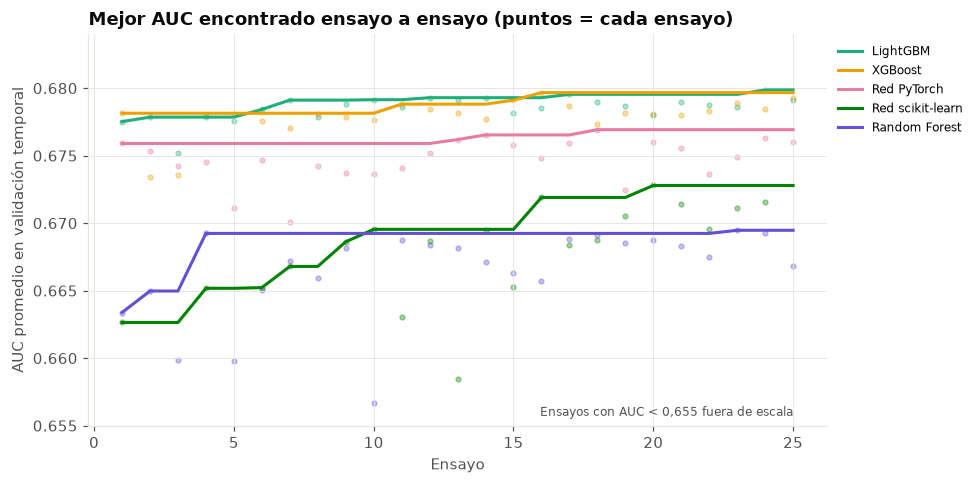

In [2]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for m in RETADORES:
    t = pd.read_csv(MOD / f"optuna_{m}.csv")
    mejor = t["value"].cummax()
    ax.plot(t["number"] + 1, mejor, color=COLOR[m], linewidth=2, label=NOMBRES[m])
    ax.scatter(t["number"] + 1, t["value"], color=COLOR[m], s=10, alpha=0.35)
ax.set_xlabel("Ensayo")
ax.set_ylabel("AUC promedio en validación temporal")
ax.set_title("Mejor AUC encontrado ensayo a ensayo (puntos = cada ensayo)")
ax.set_ylim(0.655, 0.684)
ax.text(25, 0.6555, "Ensayos con AUC < 0,655 fuera de escala", ha="right", va="bottom", fontsize=8, color=TINTA_2)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
fig.tight_layout()

## 2. Hiperparámetros ganadores

In [3]:
pd.DataFrame({NOMBRES[m]: {"hiperparámetros": ajuste[m]["params"],
                          "árboles": ajuste[m]["n_arboles"], "hardware": ajuste[m]["dispositivo"],
                          "minutos de ajuste": ajuste[m]["minutos"]} for m in RETADORES}).T

,hiperparámetros,árboles,hardware,minutos de ajuste
LightGBM,"{'learning_rate': 0.019882449251247217, 'num_l...",1051,cpu,9.3000
XGBoost,"{'learning_rate': 0.016549474528465974, 'max_d...",1125,cuda,3.2000
Red PyTorch,"{'capas': '128-64', 'dropout': 0.4849077290785...",None,cuda,12.0000
Red scikit-learn,"{'capas': '128-64-32', 'alpha': 0.000100835060...",None,cpu,10.7000
Random Forest,"{'n_estimators': 500, 'max_depth': 19, 'min_sa...",None,cpu,19.1000


## 3. El examen final: 2015 (fuera de tiempo)

Todos contra el benchmark de Lending Club.

In [4]:
y = pred["malo"]
filas = {"int_rate": discriminacion(y, pred["int_rate"])}
for m in ["logistica"] + RETADORES:
    filas[m] = resumen(y, pred[f"pd_{m}"])
tabla = pd.DataFrame(filas).T
tabla.index = [NOMBRES[i] for i in tabla.index]
tabla["Δ AUC vs Lending Club"] = tabla["auc"] - filas["int_rate"]["auc"]
tabla.sort_values("auc", ascending=False)

,auc,gini,ks,brier,pd_media,tasa_real,Δ AUC vs Lending Club
LightGBM,0.6823,0.3647,0.2652,0.1202,0.1313,0.1489,0.0039
XGBoost,0.6822,0.3645,0.2653,0.1202,0.1316,0.1489,0.0038
Red PyTorch,0.6799,0.3598,0.2624,0.1205,0.1390,0.1489,0.0014
int_rate (Lending Club),0.6784,0.3569,0.2621,NaN,NaN,NaN,0.0000
Red scikit-learn,0.6771,0.3542,0.2565,0.1212,0.1207,0.1489,-0.0013
Random Forest,0.6709,0.3417,0.2484,0.1214,0.1317,0.1489,-0.0076
Logística,0.6526,0.3052,0.2208,0.1224,0.1314,0.1489,-0.0258


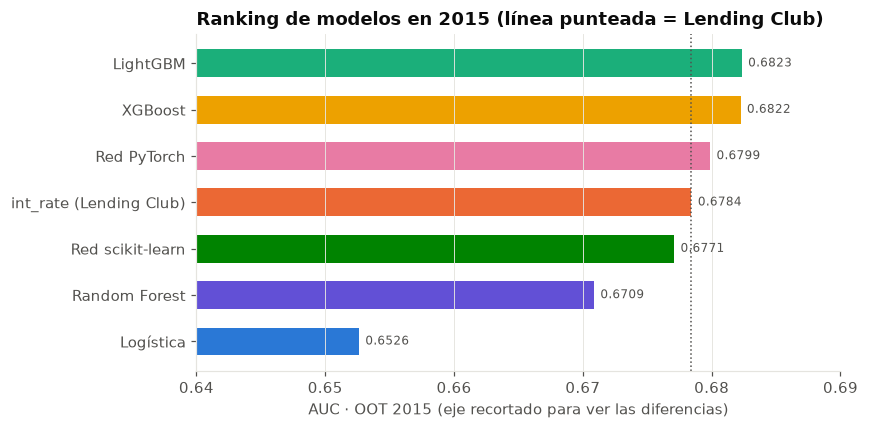

In [5]:
orden = tabla["auc"].sort_values()
claves = {v: k for k, v in NOMBRES.items()}
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(orden.index, orden.values, color=[COLOR[claves[n]] for n in orden.index], height=0.6)
for i, v in enumerate(orden.values):
    ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8, color=TINTA_2)
ax.axvline(filas["int_rate"]["auc"], color=TINTA_2, linestyle=":", linewidth=1)
ax.set_xlim(0.64, 0.69)
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC · OOT 2015 (eje recortado para ver las diferencias)")
ax.set_title("Ranking de modelos en 2015 (línea punteada = Lending Club)")
fig.tight_layout()

## 4. ¿Hubo sobreajuste a la validación?

Si los hiperparámetros se hubieran "aprendido" los trimestres de validación, el AUC de 2015 caería por debajo del de validación.

In [6]:
brecha = pd.DataFrame({
    "AUC validación (2014)": {NOMBRES[m]: ajuste[m]["auc_validacion"] for m in RETADORES},
    "AUC 2015": {NOMBRES[m]: ajuste[m]["auc_oot"] for m in RETADORES},
})
brecha["brecha (2015 − validación)"] = brecha["AUC 2015"] - brecha["AUC validación (2014)"]
brecha

,AUC validación (2014),AUC 2015,brecha (2015 − validación)
LightGBM,0.6799,0.6823,0.0025
XGBoost,0.6797,0.6822,0.0026
Red PyTorch,0.6769,0.6799,0.0030
Red scikit-learn,0.6728,0.6771,0.0043
Random Forest,0.6695,0.6709,0.0014


## 5. Curva ROC · OOT 2015

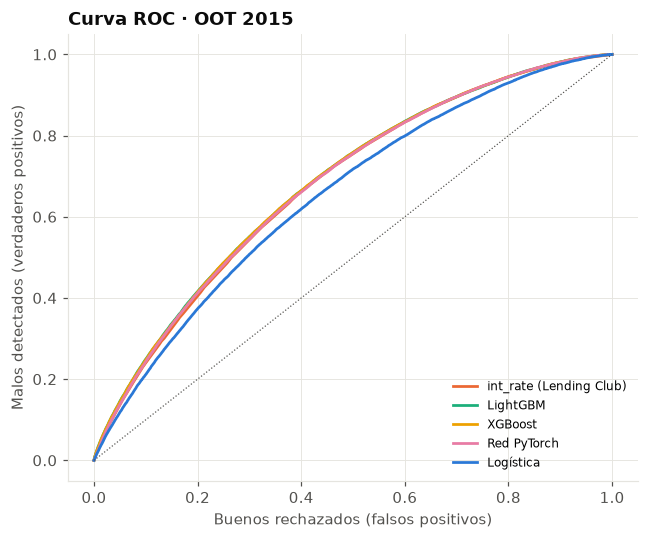

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for m in ["int_rate", "lgbm", "xgb", "torch", "logistica"]:
    score = pred["int_rate"] if m == "int_rate" else pred[f"pd_{m}"]
    fpr, tpr, _ = roc_curve(y, score)
    ax.plot(fpr, tpr, color=COLOR[m], linewidth=1.8, label=NOMBRES[m])
ax.plot([0, 1], [0, 1], color=TINTA_2, linewidth=0.8, linestyle=":")
ax.set_xlabel("Buenos rechazados (falsos positivos)")
ax.set_ylabel("Malos detectados (verdaderos positivos)")
ax.set_title("Curva ROC · OOT 2015")
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()

## 6. Tablas de eficiencia: ¿qué modelo ordena mejor la mora?

**Decil 1 = mayor riesgo** (el 10% de préstamos con peor score de cada modelo) · **decil 10 = menor riesgo**.

Cómo leerla:
- **tasa_malo** debe **bajar** del decil 1 al 10 sin saltos (monotonicidad). Cada subida es una **inversión**.
- **%_malos_acum**: si rechazo los primeros k deciles, qué parte de todos los malos evito.
- **ks**: separación acumulada entre malos y buenos; su máximo es el KS del modelo.
- **lift**: cuántas veces la mora promedio (14,9%) tiene ese decil.

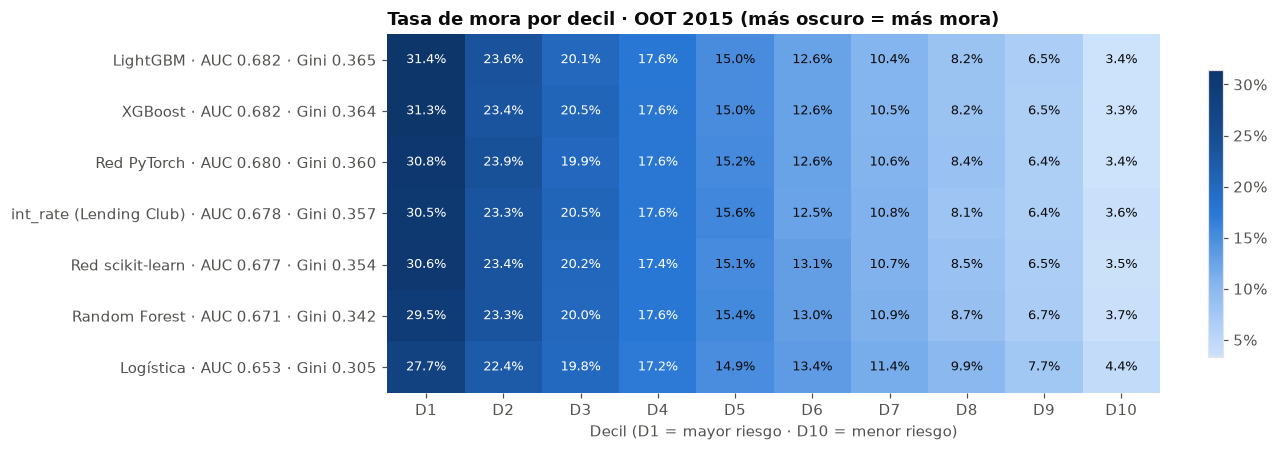

In [8]:
from credit_lab.metricas import tabla_eficiencia, resumen_orden
from matplotlib.colors import LinearSegmentedColormap

MODELOS_TABLA = ["lgbm", "xgb", "torch", "int_rate", "mlp", "rf", "logistica"]
score_de = lambda m: pred["int_rate"] if m == "int_rate" else pred[f"pd_{m}"]
eficiencia = {m: tabla_eficiencia(y, score_de(m)) for m in MODELOS_TABLA}
disc = {m: discriminacion(y, score_de(m)) for m in MODELOS_TABLA}
etiqueta = lambda m: f"{NOMBRES[m]} · AUC {disc[m]['auc']:.3f} · Gini {disc[m]['gini']:.3f}"

# Comparación lado a lado: tasa de mora por decil
matriz = pd.DataFrame({etiqueta(m): eficiencia[m]["tasa_malo"] for m in MODELOS_TABLA}).T
matriz.columns = [f"D{d}" for d in matriz.columns]

azules = LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(12.5, 4.2))
im = ax.imshow(matriz.values, cmap=azules, aspect="auto")
ax.set_xticks(range(10), matriz.columns)
ax.set_yticks(range(len(matriz)), matriz.index)
ax.grid(False)
for i in range(matriz.shape[0]):
    for j in range(10):
        v = matriz.iloc[i, j]
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.17 else TINTA)
ax.set_xlabel("Decil (D1 = mayor riesgo · D10 = menor riesgo)")
ax.set_title("Tasa de mora por decil · OOT 2015 (más oscuro = más mora)")
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, format=lambda v, _: f"{v:.0%}", shrink=0.8)
fig.tight_layout()

### Resumen: ¿quién ordena mejor?

In [9]:
orden_tabla = pd.DataFrame({NOMBRES[m]: {"auc": disc[m]["auc"], "gini": disc[m]["gini"],
                                         **resumen_orden(eficiencia[m])} for m in MODELOS_TABLA}).T
orden_tabla.sort_values("auc", ascending=False).style.format({
    "auc": "{:.4f}", "gini": "{:.4f}", "inversiones": "{:.0f}", "tasa_decil_1": "{:.1%}", "tasa_decil_10": "{:.1%}",
    "veces_d1_vs_d10": "{:.1f}×", "malos_capturados_top10%": "{:.1%}",
    "malos_capturados_top20%": "{:.1%}", "malos_capturados_top30%": "{:.1%}",
    "ks_max": "{:.3f}", "decil_ks_max": "D{:.0f}"})

,auc,gini,inversiones,tasa_decil_1,tasa_decil_10,veces_d1_vs_d10,malos_capturados_top10%,malos_capturados_top20%,malos_capturados_top30%,ks_max,decil_ks_max
LightGBM,0.6823,0.3647,0,31.4%,3.4%,9.2×,21.1%,37.0%,50.5%,0.262,D5
XGBoost,0.6822,0.3645,0,31.3%,3.3%,9.4×,21.0%,36.7%,50.5%,0.263,D5
Red PyTorch,0.6799,0.3598,0,30.8%,3.4%,9.0×,20.7%,36.7%,50.1%,0.261,D5
int_rate (Lending Club),0.6784,0.3569,0,30.5%,3.6%,8.4×,20.5%,36.2%,49.9%,0.261,D5
Red scikit-learn,0.6771,0.3542,0,30.6%,3.5%,8.8×,20.5%,36.2%,49.8%,0.254,D5
Random Forest,0.6709,0.3417,0,29.5%,3.7%,7.9×,19.8%,35.5%,48.9%,0.248,D5
Logística,0.6526,0.3052,0,27.7%,4.4%,6.3×,18.6%,33.6%,46.9%,0.218,D5


### Tabla de eficiencia completa por modelo

In [10]:
formato = {"prestamos": "{:,.0f}", "malos": "{:,.0f}", "buenos": "{:,.0f}", "tasa_malo": "{:.1%}",
           "%_malos": "{:.1%}", "%_malos_acum": "{:.1%}", "%_buenos_acum": "{:.1%}",
           "ks": "{:.3f}", "lift": "{:.2f}"}
for m in ["lgbm", "xgb", "int_rate", "logistica"]:
    display(eficiencia[m].style.format(formato).set_caption(f"<b>{NOMBRES[m]}</b> · OOT 2015 · AUC {disc[m]['auc']:.4f} · Gini {disc[m]['gini']:.4f}"))

,prestamos,malos,buenos,tasa_malo,%_malos,%_malos_acum,%_buenos_acum,ks,lift
decil,,,,,,,,,
1,"28,303","8,892","19,411",31.4%,21.1%,21.1%,8.1%,0.130,2.11
2,"28,303","6,685","21,618",23.6%,15.9%,37.0%,17.0%,0.199,1.59
3,"28,302","5,687","22,615",20.1%,13.5%,50.5%,26.4%,0.241,1.35
4,"28,303","4,974","23,329",17.6%,11.8%,62.3%,36.1%,0.262,1.18
5,"28,302","4,241","24,061",15.0%,10.1%,72.3%,46.1%,0.262,1.01
6,"28,303","3,578","24,725",12.6%,8.5%,80.8%,56.4%,0.245,0.85
7,"28,302","2,941","25,361",10.4%,7.0%,87.8%,66.9%,0.209,0.70
8,"28,303","2,322","25,981",8.2%,5.5%,93.3%,77.7%,0.157,0.55
9,"28,302","1,846","26,456",6.5%,4.4%,97.7%,88.7%,0.091,0.44


,prestamos,malos,buenos,tasa_malo,%_malos,%_malos_acum,%_buenos_acum,ks,lift
decil,,,,,,,,,
1,"28,303","8,857","19,446",31.3%,21.0%,21.0%,8.1%,0.129,2.10
2,"28,303","6,612","21,691",23.4%,15.7%,36.7%,17.1%,0.196,1.57
3,"28,302","5,799","22,503",20.5%,13.8%,50.5%,26.4%,0.241,1.38
4,"28,303","4,987","23,316",17.6%,11.8%,62.3%,36.1%,0.262,1.18
5,"28,302","4,237","24,065",15.0%,10.1%,72.4%,46.1%,0.263,1.01
6,"28,303","3,574","24,729",12.6%,8.5%,80.9%,56.4%,0.245,0.85
7,"28,302","2,962","25,340",10.5%,7.0%,87.9%,66.9%,0.210,0.70
8,"28,303","2,317","25,986",8.2%,5.5%,93.4%,77.7%,0.157,0.55
9,"28,302","1,842","26,460",6.5%,4.4%,97.8%,88.6%,0.091,0.44


,prestamos,malos,buenos,tasa_malo,%_malos,%_malos_acum,%_buenos_acum,ks,lift
decil,,,,,,,,,
1,"28,303","8,631","19,672",30.5%,20.5%,20.5%,8.2%,0.123,2.05
2,"28,303","6,600","21,703",23.3%,15.7%,36.2%,17.2%,0.190,1.57
3,"28,302","5,808","22,494",20.5%,13.8%,49.9%,26.5%,0.234,1.38
4,"28,303","4,985","23,318",17.6%,11.8%,61.8%,36.2%,0.256,1.18
5,"28,302","4,406","23,896",15.6%,10.5%,72.2%,46.1%,0.261,1.05
6,"28,303","3,534","24,769",12.5%,8.4%,80.6%,56.4%,0.242,0.84
7,"28,302","3,043","25,259",10.8%,7.2%,87.8%,66.9%,0.210,0.72
8,"28,303","2,288","26,015",8.1%,5.4%,93.3%,77.7%,0.156,0.54
9,"28,302","1,809","26,493",6.4%,4.3%,97.6%,88.7%,0.089,0.43


,prestamos,malos,buenos,tasa_malo,%_malos,%_malos_acum,%_buenos_acum,ks,lift
decil,,,,,,,,,
1,"28,303","7,845","20,458",27.7%,18.6%,18.6%,8.5%,0.101,1.86
2,"28,303","6,327","21,976",22.4%,15.0%,33.6%,17.6%,0.160,1.50
3,"28,302","5,608","22,694",19.8%,13.3%,46.9%,27.0%,0.199,1.33
4,"28,303","4,878","23,425",17.2%,11.6%,58.5%,36.8%,0.218,1.16
5,"28,302","4,231","24,071",14.9%,10.0%,68.6%,46.8%,0.218,1.00
6,"28,303","3,798","24,505",13.4%,9.0%,77.6%,56.9%,0.207,0.90
7,"28,302","3,226","25,076",11.4%,7.7%,85.2%,67.3%,0.179,0.77
8,"28,303","2,800","25,503",9.9%,6.6%,91.9%,77.9%,0.140,0.66
9,"28,302","2,182","26,120",7.7%,5.2%,97.1%,88.8%,0.083,0.52


## 7. GPU vs. CPU

| Modelo | Tiempo por entrenamiento (CPU → GPU) | Aceleración |
|---|---|---|
| XGBoost | 13–20 s → 1,7–4,5 s | **4,6×–7,8×**, mismo AUC |
| Red neuronal | scikit-learn CPU ~20 s/ensayo vs PyTorch GPU ~45 s/ensayo | Ninguna: red pequeña con lotes chicos; la GPU pasa más tiempo recibiendo instrucciones que calculando |

La red PyTorch gana a la de scikit-learn por **arquitectura** (BatchNorm, Dropout, AdamW), no por la GPU.

---
## ✍️ Conclusiones de Neider

1. Con el mismo esfuerzo de ajuste para todos, LightGBM (0,6823) y XGBoost (0,6822) le ganan al score de Lending Club (0,6784) usando solo variables públicas de la solicitud. Falta probar si la diferencia es significativa.
2. Los boosting separan mejor los extremos: el peor decil tiene 9,2 veces más malos que el mejor, contra 8,5 veces de Lending Club y 6,3 de la logística. Eso es lo que más importa para aprobar o rechazar.
3. No hubo sobreajuste a la validación: en los 5 modelos el AUC de 2015 quedó igual o por encima del de 2014. Validar con dos trimestres en vez de uno funcionó.
4. La GPU sirvió para XGBoost (de 13 a 3 minutos), pero no para la red neuronal: con una red pequeña no se aprovecha. La red de PyTorch ganó por arquitectura, no por hardware.